# 0.5× Object-Space Telecentric Objective for Machine Vision — designed with Optiland

**Author:** Lorenzo Fratini

A telecentric objective for **inspection and gauging** (edges, holes, scratches, small defects) with a 2/3" machine-vision camera.
In **object-space telecentric** lenses all chief rays are parallel to the axis in front of the lens: the magnification does not change when the part moves slightly in focus, there is no perspective error, and the side walls of holes are not seen. This is why they are the standard optics for optical metrology.

The specification is modelled on commercial 0.5× / 110 mm WD telecentric lenses (e.g. Edmund Optics CompactTL: NA 0.028, f/9, 2/3" sensor, typical telecentricity 0.05°, typical distortion 0.02–0.035 %).

| # | Rule | Requirement |
|---|---|---|
| 1 | Magnification | −0.50× ± 1 % |
| 2 | Sensor | 2/3": image semi-height 5.5 mm (Ø 11 mm image circle) |
| 3 | Object field | semi-height 11 mm (Ø 22 mm) |
| 4 | Working distance | 110 mm ± 1 mm (object → first vertex) |
| 5 | Object-side NA | 0.028 (≈ f/9 working on the image side) |
| 6 | **Object-space telecentricity** | real chief-ray angle ≤ 0.10° at every field |
| 7 | **Distortion** | ≤ 0.10 % at every field |
| 8 | Image-side chief-ray angle | ≤ 10° (sensor micro-lenses) |
| 9 | Wavelengths | 0.486, 0.588, 0.656 µm, equal weights (white LED illumination) |
| 10 | Fields (object height) | 0, 5.5, 7.7, 9.5, 11 mm |
| 11 | Elements | 3 – 8, spherical only, catalog glasses |
| 12 | Stop | inside the lens |
| 13 | Clear diameter | ≤ 40 mm |
| 14 | Lens length | first vertex → image ≤ 180 mm |
| 15 | Back focal distance | ≥ 12 mm (C-mount camera) |
| 16 | Center / edge thickness | ≥ 2 mm / ≥ 1 mm |
| 17 | Penalty | P penalises every rule |

**Goal:** the best diffraction-limited performance → minimise Σ (polychromatic RMS spot)² + P, and verify with RMS wavefront error / Strehl ratio and the polychromatic MTF against real sensor pixel sizes.

In [1]:
# Install Optiland (needed on Google Colab; harmless if already installed)
%pip install -q optiland

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from importlib.metadata import version

from optiland.optic import Optic
from optiland.distribution import HexagonalDistribution
from optiland.optimization.operand.lens import LensOperand
from optiland.analysis import SpotDiagram
from optiland.mtf import ScalarFFTMTF
from optiland.wavefront import OPD

print("Optiland version:", version("optiland"))

Optiland version: 0.6.2


## 1. Specification

In [3]:
MAG_TARGET, MAG_TOL = -0.50, 0.01         # +-1 %
OBJ_HEIGHTS = [0.0, 5.5, 7.7, 9.5, 11.0]  # mm, object semi-heights
WD = 110.0                                # mm, object to first vertex
OBJECT_NA = 0.028
TELE_MAX = 0.10                           # deg, object-space chief-ray angle
DIST_MAX = 0.10                           # %
CRA_MAX = 10.0                            # deg, image-side chief-ray angle
SEMI_AP_MAX = 20.0                        # mm (clear diameter <= 40 mm)
LENGTH_MAX = 180.0                        # mm, first vertex to image
BFD_MIN = 12.0                            # mm
CT_MIN, ET_MIN = 2.0, 1.0                 # mm
N_ELEM = (3, 8)
WAVELENGTHS = [0.486, 0.588, 0.656]       # um, equal weights
PRIMARY_WL = 0.588
PENALTY_WEIGHT = 1.0

## 2. Final design (8 elements)

**Front group** — weak positive meniscus + cemented achromat (N-BK7 / N-SF5); the **aperture stop sits at its rear focal point**, which makes the lens telecentric in object space.
**Rear group** — N-SK16 crown, F2 flint, two N-LAK9 positive lenses, and a negative **field flattener** (N-SF5) close to the sensor.
Surfaces 8 and 16 were driven flat by the optimiser (plano surfaces, written as `np.inf`).

In [4]:
# (radius, thickness after the surface, glass or None for air, is_stop) for surfaces 1..16
FINAL_PRESCRIPTION = [
    (110.51424149994928, 4.205250500633229, "N-BK7", False),
    (385.9181772896871, 21.6745750833336, None, False),
    (58.228320936899024, 5.613187011382035, "N-BK7", False),
    (-49.03650651214213, 12.030621439656539, "N-SF5", False),
    (-191.45263128105577, 70.1091400643989, None, False),
    (np.inf, 0.5105600867552056, None, True),                    # aperture stop
    (38.39931054462775, 3.3899045453887737, "N-SK16", False),
    (np.inf, 2.964409912791325, None, False),
    (-23.71231171292081, 7.168212902996942, "F2", False),
    (26.18186437644324, 3.4538000137228124, None, False),
    (51.407788865725564, 3.2809361334426796, "N-LAK9", False),
    (-35.025556363685006, 8.494965746365665, None, False),
    (99.79894365480062, 3.1035817642288066, "N-LAK9", False),
    (-30.82006238538981, 11.430052395749556, None, False),
    (-23.921820982220797, 4.492823653841128, "N-SF5", False),     # field flattener
    (np.inf, 17.08604323166628, None, False),                     # -> BFD to the sensor
]


def build_lens(prescription, name="0.5x object-telecentric objective"):
    lens = Optic(name=name)
    lens.surfaces.add(index=0, radius=np.inf, thickness=WD)       # object plane, WD = 110 mm
    for k, (r, t, glass, stop) in enumerate(prescription, start=1):
        kw = dict(index=k, radius=r, thickness=t, is_stop=stop)
        if glass:
            kw["material"] = (glass, "schott")
        lens.surfaces.add(**kw)
    lens.surfaces.add(index=len(prescription) + 1)                # image (sensor)
    lens.set_aperture(aperture_type="objectNA", value=OBJECT_NA)
    lens.fields.set_type("object_height")
    for h in OBJ_HEIGHTS:
        lens.fields.add(y=h)
    for wl in WAVELENGTHS:
        lens.wavelengths.add(value=wl, is_primary=(wl == PRIMARY_WL))
    return lens


lens = build_lens(FINAL_PRESCRIPTION)
lens.info()

╒════╤═══════════════╤═══════════╤═══════════╤═════════════╤════════════╤═════════╤═════════════════╕
│    │ Type          │ Comment   │    Radius │   Thickness │ Material   │   Conic │   Semi-aperture │
╞════╪═══════════════╪═══════════╪═══════════╪═════════════╪════════════╪═════════╪═════════════════╡
│  0 │ Planar        │           │  inf      │   110       │ Air        │       0 │        11       │
│  1 │ Standard      │           │  110.514  │     4.20525 │ N-BK7      │       0 │        14.0786  │
│  2 │ Standard      │           │  385.918  │    21.6746  │ Air        │       0 │        13.9736  │
│  3 │ Standard      │           │   58.2283 │     5.61319 │ N-BK7      │       0 │        13.5589  │
│  4 │ Standard      │           │  -49.0365 │    12.0306  │ N-SF5      │       0 │        13.0428  │
│  5 │ Standard      │           │ -191.453  │    70.1091  │ Air        │       0 │        12.3378  │
│  6 │ Stop - Planar │           │  inf      │     0.51056 │ Air        │       0 

## 3. Metrics and penalty term P

* **Polychromatic RMS spot** — all rays of the three wavelengths about their common centroid (lateral colour included).
* **Telecentricity** — angle of the real chief ray (through the stop centre) in object space.
* **Distortion** — real chief-ray image height vs. the near-axis magnification.
* **Image CRA** — chief-ray angle arriving on the sensor.
* Edge thickness and clear diameter use Optiland's semi-aperture convention (|marginal| + |chief| paraxial ray height), refreshed at every evaluation.

Near perfect telecentricity the entrance pupil is at ±infinity and Optiland may trace the chief ray with reversed direction cosines (same line, opposite sense), so angles are computed as atan(M/N), which is the same in both cases.

In [5]:
def thicknesses(optic):
    z = np.asarray(optic.surfaces.positions).ravel()
    return np.diff(z[1:])


def elements(optic):
    out = []
    for i in range(1, optic.surfaces.num_surfaces - 1):
        if float(np.squeeze(optic.surfaces[i].material_post.n(PRIMARY_WL))) > 1.01:
            out.append((i, i + 1))
    return out


def spot_sizes(optic, rings=16):
    # Polychromatic RMS spot radius (mm) per field, about the common centroid
    d = HexagonalDistribution()
    d.generate_points(rings)
    px, py = np.asarray(d.x), np.asarray(d.y)
    nf, npup = len(OBJ_HEIGHTS), len(px)
    Hy = np.repeat(np.array(OBJ_HEIGHTS) / OBJ_HEIGHTS[-1], npup)
    Px, Py = np.tile(px, nf), np.tile(py, nf)
    xs, ys = [], []
    for wl in WAVELENGTHS:
        r = optic.trace_generic(np.zeros_like(Hy), Hy, Px, Py, wl)
        xs.append(np.asarray(r.x).reshape(nf, npup))
        ys.append(np.asarray(r.y).reshape(nf, npup))
    x, y = np.concatenate(xs, 1), np.concatenate(ys, 1)
    rms = np.sqrt(np.mean((x - x.mean(1, keepdims=True)) ** 2 + (y - y.mean(1, keepdims=True)) ** 2, 1))
    return np.where(np.isfinite(rms), rms, 10.0)


def chief_ray_data(optic, near_axis=0.05):
    h = np.array([near_axis] + OBJ_HEIGHTS[1:])
    Hy = h / OBJ_HEIGHTS[-1]
    z0 = np.zeros_like(Hy)
    optic.trace_generic(z0, Hy, z0, z0, PRIMARY_WL)
    M, N, y = (np.asarray(a) for a in (optic.surfaces.M, optic.surfaces.N, optic.surfaces.y))
    obj_angle = np.degrees(np.arctan(M[0] / N[0]))     # leaving the object
    img_angle = np.degrees(np.arctan(M[-2] / N[-2]))   # arriving on the sensor
    mag0 = y[-1][0] / h[0]
    dist = 100 * (y[-1][1:] - mag0 * h[1:]) / (mag0 * h[1:])
    return {"mag": float(mag0), "tele": obj_angle[1:], "cra": img_angle[1:], "dist": dist}


def system_values(optic):
    optic.updater.update_paraxial()                     # refresh semi-apertures
    t = thicknesses(optic)
    elems = elements(optic)
    stop = optic.surfaces.stop_index
    cr = chief_ray_data(optic)
    n = optic.surfaces.num_surfaces
    return {
        "mag": cr["mag"],
        "tele": [0.0] + list(cr["tele"]),
        "cra": [0.0] + list(cr["cra"]),
        "dist": [0.0] + list(cr["dist"]),
        "length": float(t.sum()),
        "bfd": float(t[-1]),
        "semi": [float(np.squeeze(optic.surfaces[i].semi_aperture)) for i in range(1, n - 1)],
        "ct": [float(t[a - 1]) for a, _ in elems],
        "et": [float(np.squeeze(LensOperand.edge_thickness(optic, a))) for a, _ in elems],
        "n_elements": len(elems),
        "stop_inside": elems[0][0] < stop < elems[-1][1],
        "working_fno": abs(cr["mag"]) / (2 * OBJECT_NA),
    }


def violations(optic, margin=None):
    # Normalised violation of every rule (0 = satisfied); `margin` tightens the limits during optimisation
    m = margin or {k: 0.0 for k in ("mag", "tele", "dist", "cra", "semi", "len", "bfd", "et")}
    v = system_values(optic)
    return {
        "Magnification": max(0.0, abs(v["mag"] / MAG_TARGET - 1) - (MAG_TOL - m["mag"])) / MAG_TOL,
        "Telecentricity": sum(max(0.0, abs(a) - (TELE_MAX - m["tele"])) for a in v["tele"]) / TELE_MAX,
        "Distortion": sum(max(0.0, abs(d) - (DIST_MAX - m["dist"])) for d in v["dist"]) / DIST_MAX,
        "Image CRA": sum(max(0.0, abs(a) - (CRA_MAX - m["cra"])) for a in v["cra"]) / CRA_MAX,
        "Clear diameter": sum(max(0.0, s - (SEMI_AP_MAX - m["semi"])) for s in v["semi"]) / SEMI_AP_MAX,
        "Lens length": max(0.0, v["length"] - (LENGTH_MAX - m["len"])) / LENGTH_MAX,
        "BFD": max(0.0, BFD_MIN + m["bfd"] - v["bfd"]) / BFD_MIN,
        "Center thickness": sum(max(0.0, CT_MIN - t) for t in v["ct"]) / CT_MIN,
        "Edge thickness": sum(max(0.0, ET_MIN + m["et"] - t) for t in v["et"]) / ET_MIN,
        "Elements (3-8)": float(not N_ELEM[0] <= v["n_elements"] <= N_ELEM[1]),
        "Stop inside": float(not v["stop_inside"]),
    }


def penalty(optic, margin=None):
    # P = sum_i (W * v_i)^2  -- penalises every constraint violation
    return sum((PENALTY_WEIGHT * x) ** 2 for x in violations(optic, margin).values())


def rms_wavefront(optic):
    # RMS wavefront error (waves) per field and wavelength, centroid reference
    out = np.zeros((len(OBJ_HEIGHTS), len(WAVELENGTHS)))
    for i, h in enumerate(OBJ_HEIGHTS):
        for j, wl in enumerate(WAVELENGTHS):
            out[i, j] = float(np.squeeze(OPD(optic, (0.0, h / OBJ_HEIGHTS[-1]), wl,
                                             num_rays=16, strategy="centroid").rms()))
    return out

## 4. Results

In [6]:
v = system_values(lens)
spots_um = spot_sizes(lens) * 1e3
wfe = rms_wavefront(lens)
strehl = np.exp(-(2 * np.pi * wfe) ** 2)               # Marechal approximation
airy_um = 1.22 * PRIMARY_WL * v["working_fno"]

perf = pd.DataFrame({
    "Object h [mm]": OBJ_HEIGHTS,
    "Poly RMS spot [um]": spots_um,
    "RMS WFE 486 nm [waves]": wfe[:, 0],
    "RMS WFE 588 nm [waves]": wfe[:, 1],
    "RMS WFE 656 nm [waves]": wfe[:, 2],
    "Worst Strehl": strehl.min(1),
    "Telecentricity [deg]": v["tele"],
    "Distortion [%]": v["dist"],
    "Image CRA [deg]": v["cra"],
})
display(perf.style.format(precision=4).hide(axis="index"))
print(f"Working F/# = {v['working_fno']:.2f}    Airy radius (588 nm) = {airy_um:.2f} um")
print(f"Mean polychromatic RMS spot = {spots_um.mean():.3f} um  (= {spots_um.mean() / airy_um:.2f} x Airy radius)")
print(f"Worst RMS WFE = {wfe.max():.4f} waves  (diffraction-limited: <= 0.0714 waves, Strehl >= 0.8)")

Object h [mm],Poly RMS spot [um],RMS WFE 486 nm [waves],RMS WFE 588 nm [waves],RMS WFE 656 nm [waves],Worst Strehl,Telecentricity [deg],Distortion [%],Image CRA [deg]
0.0000,2.1399,0.0414,0.0265,0.0670,0.8378,0.0000,0.0000,0.0000
5.5000,1.7479,0.0177,0.0134,0.0400,0.9389,-0.0007,0.0154,-3.0340
7.7000,1.8051,0.0191,0.0295,0.0219,0.9663,-0.0010,0.0184,-4.2465
9.5000,2.0570,0.0460,0.0433,0.0154,0.9200,-0.0012,0.0080,-5.2381
11.0000,2.7029,0.0892,0.0592,0.0316,0.7303,-0.0014,-0.0172,-6.0644


Working F/# = 8.93    Airy radius (588 nm) = 6.41 um
Mean polychromatic RMS spot = 2.091 um  (= 0.33 x Airy radius)
Worst RMS WFE = 0.0892 waves  (diffraction-limited: <= 0.0714 waves, Strehl >= 0.8)


In [7]:
checks = pd.DataFrame([
    ("Magnification",           f"{v['mag']:.4f}", "-0.495 ... -0.505", abs(v["mag"] / MAG_TARGET - 1) <= MAG_TOL),
    ("Working distance [mm]",   f"{WD:.1f}", "110 +- 1", True),
    ("Object NA",               f"{OBJECT_NA}", "0.028", True),
    ("Max telecentricity [deg]", f"{max(abs(a) for a in v['tele']):.4f}", "<= 0.10", max(abs(a) for a in v["tele"]) <= TELE_MAX),
    ("Max |distortion| [%]",    f"{max(abs(d) for d in v['dist']):.4f}", "<= 0.10", max(abs(d) for d in v["dist"]) <= DIST_MAX),
    ("Max image CRA [deg]",     f"{max(abs(a) for a in v['cra']):.2f}", "<= 10", max(abs(a) for a in v["cra"]) <= CRA_MAX),
    ("Max clear diameter [mm]", f"{2 * max(v['semi']):.2f}", "<= 40", max(v["semi"]) <= SEMI_AP_MAX),
    ("Lens length [mm]",        f"{v['length']:.2f}", "<= 180", v["length"] <= LENGTH_MAX),
    ("BFD [mm]",                f"{v['bfd']:.2f}", ">= 12", v["bfd"] >= BFD_MIN),
    ("Elements",                f"{v['n_elements']}", "3 - 8", N_ELEM[0] <= v["n_elements"] <= N_ELEM[1]),
    ("Stop inside the lens",    f"{v['stop_inside']}", "True", v["stop_inside"]),
    ("Min center thickness [mm]", f"{min(v['ct']):.3f}", ">= 2", min(v["ct"]) >= CT_MIN),
    ("Min edge thickness [mm]",   f"{min(v['et']):.3f}", ">= 1", min(v["et"]) >= ET_MIN),
], columns=["Rule", "Value", "Limit", "OK"])
display(checks.style.hide(axis="index"))

P = penalty(lens)
print(f"Penalty P = {P:.3e}")
print(f"Score = sum(RMS^2) + P = {np.sum((spots_um * 1e-3) ** 2) + P:.4e} mm^2")

Rule,Value,Limit,OK
Magnification,-0.5000,-0.495 ... -0.505,True
Working distance [mm],110.0,110 +- 1,True
Object NA,0.028,0.028,True
Max telecentricity [deg],0.0014,<= 0.10,True
Max |distortion| [%],0.0184,<= 0.10,True
Max image CRA [deg],6.06,<= 10,True
Max clear diameter [mm],28.16,<= 40,True
Lens length [mm],179.01,<= 180,True
BFD [mm],17.09,>= 12,True
Elements,8,3 - 8,True


Penalty P = 0.000e+00
Score = sum(RMS^2) + P = 2.2430e-05 mm^2


## 5. Visualisations

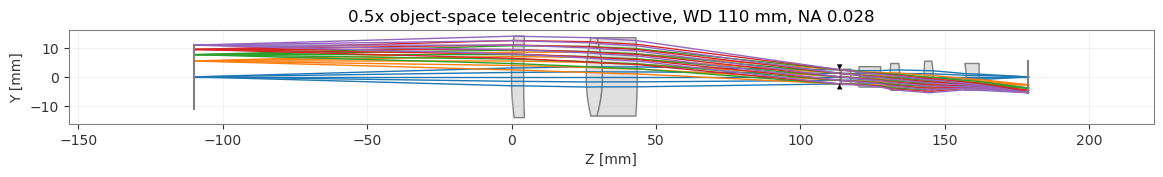

In [8]:
lens.draw(num_rays=5, figsize=(14, 4))
plt.title("0.5x object-space telecentric objective, WD 110 mm, NA 0.028")
plt.show()

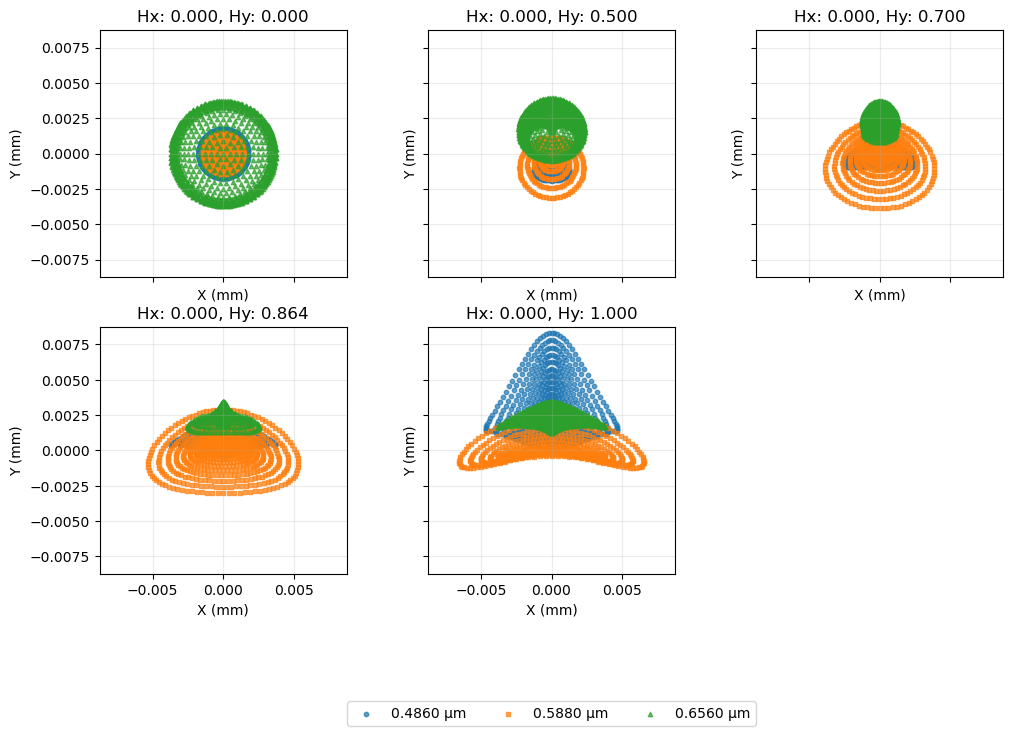

In [9]:
SpotDiagram(lens, num_rings=16, reference="centroid").view()
plt.show()

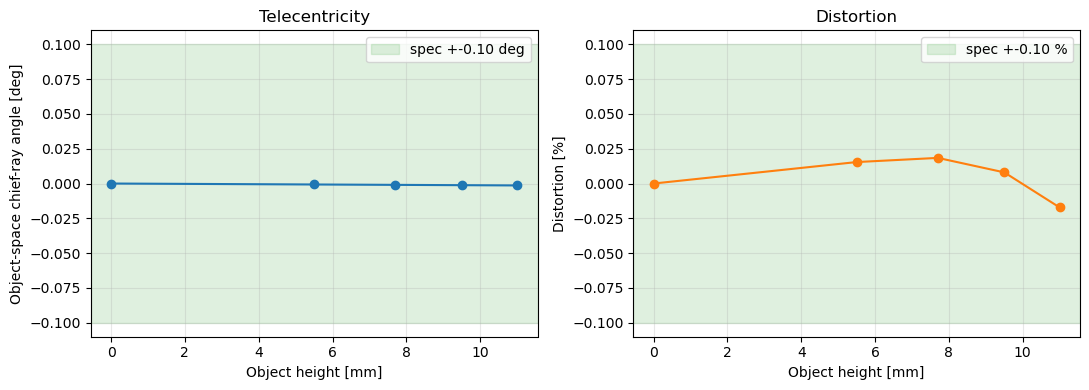

In [10]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(OBJ_HEIGHTS, v["tele"], "o-")
a1.axhspan(-TELE_MAX, TELE_MAX, color="tab:green", alpha=0.15, label="spec +-0.10 deg")
a1.set(xlabel="Object height [mm]", ylabel="Object-space chief-ray angle [deg]", title="Telecentricity")
a1.legend(); a1.grid(alpha=0.3)
a2.plot(OBJ_HEIGHTS, v["dist"], "o-", color="tab:orange")
a2.axhspan(-DIST_MAX, DIST_MAX, color="tab:green", alpha=0.15, label="spec +-0.10 %")
a2.set(xlabel="Object height [mm]", ylabel="Distortion [%]", title="Distortion")
a2.legend(); a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. MTF and match with real machine-vision sensors

Optiland's FFT MTF is monochromatic: it is computed at each wavelength and the three curves are averaged (equal weights) on a common frequency axis — an approximation of the polychromatic MTF.
The vertical lines are the Nyquist frequencies 1/(2·pixel) of typical 2/3"-class sensors.

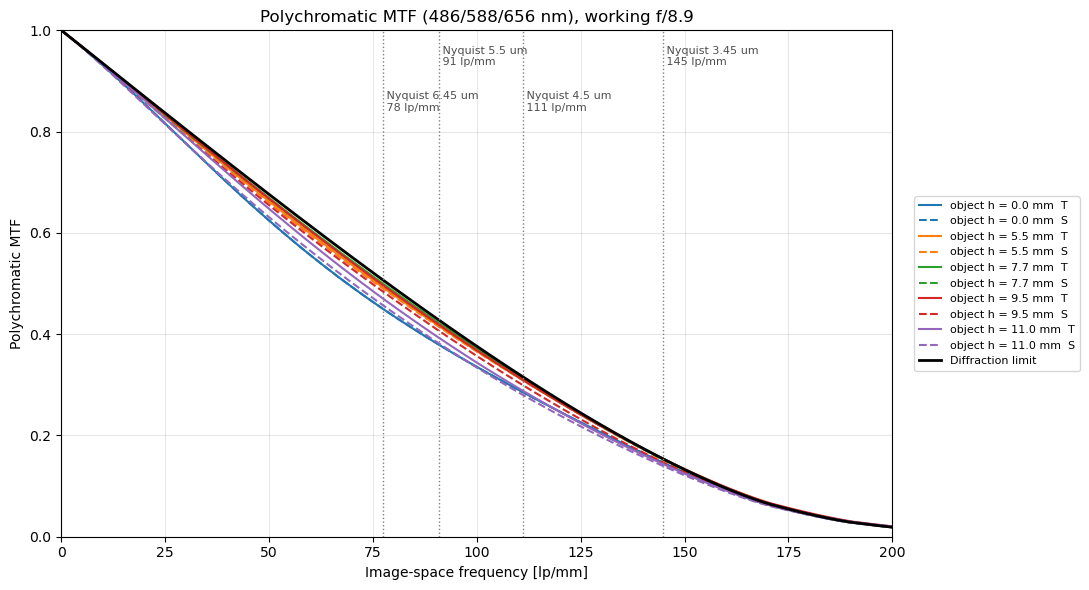

In [11]:
SENSORS = [
    ('Sony IMX250 / IMX264 (5 MP, 2/3")', 3.45),
    ("Generic 4.5 um pixel", 4.5),
    ("Generic 5.5 um pixel", 5.5),
    ('Sony ICX285 (1.4 MP CCD, 2/3")', 6.45),
]
fno = v["working_fno"]
freq = np.linspace(0, 1 / (min(WAVELENGTHS) * 1e-3 * fno), 400)
nf = len(OBJ_HEIGHTS)
tang, sag, diff_lim = np.zeros((nf, freq.size)), np.zeros((nf, freq.size)), np.zeros(freq.size)
for wl in WAVELENGTHS:
    mtf = ScalarFFTMTF(lens, fields="all", wavelength=wl, num_rays=128, grid_size=512)
    for k in range(nf):
        tang[k] += np.interp(freq, np.asarray(mtf.freq_tang[k]), np.asarray(mtf.mtf[k][0]), right=0) / 3
        sag[k] += np.interp(freq, np.asarray(mtf.freq_sag[k]), np.asarray(mtf.mtf[k][1]), right=0) / 3
    u = np.clip(freq * wl * 1e-3 * fno, 0, 1)
    diff_lim += (2 / np.pi) * (np.arccos(u) - u * np.sqrt(1 - u ** 2)) / 3

fig, ax = plt.subplots(figsize=(11, 6))
for k, h in enumerate(OBJ_HEIGHTS):
    ax.plot(freq, tang[k], color=f"C{k}", label=f"object h = {h:.1f} mm  T")
    ax.plot(freq, sag[k], color=f"C{k}", ls="--", label=f"object h = {h:.1f} mm  S")
ax.plot(freq, diff_lim, "k", lw=2, label="Diffraction limit")
for j, (name, p) in enumerate(SENSORS):
    ny = 1 / (2 * p * 1e-3)
    ax.axvline(ny, color="0.5", ls=":", lw=1)
    ax.text(ny, 0.97 - 0.09 * (j % 2), f" Nyquist {p} um\n {ny:.0f} lp/mm", fontsize=8, va="top", color="0.3")
ax.set(xlim=(0, 200), ylim=(0, 1), xlabel="Image-space frequency [lp/mm]", ylabel="Polychromatic MTF",
       title=f"Polychromatic MTF (486/588/656 nm), working f/{fno:.1f}")
ax.grid(alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 0.5), loc="center left", fontsize=8)
plt.tight_layout(); plt.show()

In [12]:
rows = []
for name, p in SENSORS:
    ny = 1 / (2 * p * 1e-3)
    worst = lambda f: min(min(np.interp(f, freq, tang[k]), np.interp(f, freq, sag[k])) for k in range(nf))
    rows.append({"Sensor": name, "Pixel [um]": p, "Nyquist [lp/mm]": round(ny, 1),
                 "Object-side pixel [um]": round(p / abs(v["mag"]), 2),
                 "MTF diffraction limit @ Nyquist": round(float(np.interp(ny, freq, diff_lim)), 3),
                 "MTF design @ Nyquist (worst field)": round(float(worst(ny)), 3),
                 "MTF design @ Nyquist/2 (worst field)": round(float(worst(ny / 2)), 3)})
display(pd.DataFrame(rows).style.format({"Pixel [um]": "{:.2f}", "Nyquist [lp/mm]": "{:.1f}", "Object-side pixel [um]": "{:.1f}",
                                         "MTF diffraction limit @ Nyquist": "{:.3f}", "MTF design @ Nyquist (worst field)": "{:.3f}",
                                         "MTF design @ Nyquist/2 (worst field)": "{:.3f}"}).hide(axis="index"))

Sensor,Pixel [um],Nyquist [lp/mm],Object-side pixel [um],MTF diffraction limit @ Nyquist,MTF design @ Nyquist (worst field),MTF design @ Nyquist/2 (worst field)
"Sony IMX250 / IMX264 (5 MP, 2/3"")",3.45,144.9,6.9,0.153,0.139,0.478
Generic 4.5 um pixel,4.50,111.1,9.0,0.316,0.280,0.585
Generic 5.5 um pixel,5.50,90.9,11.0,0.428,0.379,0.657
"Sony ICX285 (1.4 MP CCD, 2/3"")",6.45,77.5,12.9,0.506,0.449,0.708


**Interpretation**

* The design MTF follows the diffraction limit closely at every field: the lens is (essentially) **diffraction-limited**, so the resolution is set by the specified NA (0.028, ≈ f/9), not by aberrations.
* With **4.5–6.45 µm pixels** the match is good (≈ 28–45 % contrast at Nyquist; a common machine-vision rule of thumb is ≥ 20–30 %).
* With **3.45 µm pixels** (5 MP 2/3" sensors) the contrast at Nyquist is ≈ 14 %, which is the physical limit at f/9 (a perfect lens gives ≈ 15 %): the Airy disk (Ø ≈ 12.8 µm) spans ≈ 3.7 pixels and the sensor oversamples the optics. It still delivers ≈ 48 % at half-Nyquist. Exploiting 3.45 µm pixels fully would need an object NA of ≈ 0.04–0.05, at the cost of depth of field.

## 7. How the design was obtained

Merit function: Σ (polychromatic RMS spot)² over the 5 fields + every term of P (with a small safety margin on the limits), plus smooth targets for magnification, telecentricity and distortion (the one-sided P terms have kinks at the limits that stall a gradient solver).
Optimiser: Optiland `LeastSquares` (damped least squares, SciPy `trf` with variable bounds and Jacobian-based scaling).

| Step | Layout | Mean RMS spot | What limited it / what was learned |
|---|---|---|---|
| 1 | Two cemented achromats, stop at the rear focus of the front one (4 el.) | 23 µm | Field curvature: two positive groups, Petzval radius ≈ 51 mm |
| 2 | + negative field flattener near the sensor (5 el.) | 20 µm | ≈ 1.1 mm of field curvature and astigmatism generated by the telecentric front group (chief rays up to 14 mm off-axis, stop ≈ 90 mm away) |
| 3 | Front meniscus + achromat, **Cooke-triplet rear group**, field flattener (7 el.) | 15 µm | Flat field, but a large balanced spherical aberration (ray fan ±18 µm on axis) |
| 4 | 6 parallel restarts (glass swaps, random radius perturbations) | 11.4 µm | Per-surface Seidel analysis: one rear surface (R = −15 mm) produced most of the spherical aberration |
| 5 | **Split that lens into two N-LAK9 lenses** (8 el.) | **2.1 µm** | Diffraction-limited |

The decisive step was a classic lens-design move — splitting the most strongly bent positive lens and raising its refractive index — identified from the per-surface aberration analysis rather than from longer optimisation.

The cell below reproduces step 5 (8-element start → final design). It is slow (≈ 11 min on a fast, idle PC; several hours on a loaded one or on free Colab), so it is switched off by default; set `RUN_OPTIMIZATION = True` to run it.

In [13]:
RUN_OPTIMIZATION = False

import inspect
from types import SimpleNamespace
from optiland import optimization
from optiland.optimization.operand import operand_registry
from optiland.optimization.optimizer.scipy import least_squares as _lsq_module
from scipy import optimize as _scipy_optimize

# Starting point of step 5: best 7-element design with its strongest positive lens
# (R = 39.79 / -15.29) split into two half-power N-LAK9 lenses
START_8EL = [
    (121.84599381134633, 3.23085949090799, "N-BK7", False),
    (281.52201883772887, 13.775856098066226, None, False),
    (52.241066063574934, 5.485442895525296, "N-BK7", False),
    (-42.602791804739695, 12.363614353471903, "N-SF5", False),
    (-158.78366785598885, 70.12855446284522, None, False),
    (np.inf, 1.9852620953994915, None, True),
    (39.90164525059547, 3.351574567231836, "N-SK16", False),
    (14694.901446076337, 2.7520947532349, None, False),
    (-54.42323599209593, 2.0070195929123145, "F2", False),
    (16.470410061118944, 4.198946466222566, None, False),
    (2 * 39.786043257285876, 2.5, "N-LAK9", False),
    (2 * -15.292606217204252, 0.5, None, False),
    (2 * 39.786043257285876, 2.5, "N-LAK9", False),
    (2 * -15.292606217204252, 13.74006913529972, None, False),
    (-36.89081215606893, 4.7125478306078605, "N-SF5", False),
    (284237.3489209562, 17.837125398630747, None, False),
]
MARGIN = {"mag": 0.003, "tele": 0.03, "dist": 0.02, "cra": 0.5, "semi": 0.3, "len": 1.0, "bfd": 0.3, "et": 0.05}

def _memo(fn):
    # Every operand asks for the same traces: compute them once per lens state
    cache = {}
    def wrapped(optic, *args, **kwargs):
        n = optic.surfaces.num_surfaces
        key = (tuple(float(np.squeeze(optic.surfaces[i].geometry.radius)) for i in range(1, n))
               + tuple(np.round(np.asarray(optic.surfaces.positions).ravel(), 12))
               + (id(optic), args, tuple(kwargs.items())))
        if cache.get("key") != key:
            cache["key"], cache["val"] = key, fn(optic, *args, **kwargs)
        return cache["val"]
    return wrapped

spot_sizes = _memo(spot_sizes)
system_values = _memo(system_values)

operand_registry.register("tc_spot", lambda optic, k: float(spot_sizes(optic, rings=6)[k]), overwrite=True)
operand_registry.register("tc_constraint", lambda optic, name: violations(optic, MARGIN)[name], overwrite=True)
operand_registry.register("tc_tele", lambda optic, k: float(system_values(optic)["tele"][k]), overwrite=True)
operand_registry.register("tc_dist", lambda optic, k: float(system_values(optic)["dist"][k]), overwrite=True)
operand_registry.register("tc_mag", lambda optic: float(system_values(optic)["mag"]), overwrite=True)

# Older SciPy (< 1.16) has no `callback` in least_squares; x_scale="jac" balances radii vs thicknesses
_accepts_cb = "callback" in inspect.signature(_scipy_optimize.least_squares).parameters
def _least_squares(*args, callback=None, **kwargs):
    if _accepts_cb:
        kwargs["callback"] = callback
    return _scipy_optimize.least_squares(*args, x_scale="jac", **kwargs)
_lsq_module.optimize = SimpleNamespace(least_squares=_least_squares)


def optimise(t, max_blocks=30, nfev_per_block=25, rel_tol=3e-3):
    p = optimization.OptimizationProblem()
    nf = len(OBJ_HEIGHTS)
    for k in range(nf):
        p.add_operand("tc_spot", target=0.0, weight=1.0, input_data={"optic": t, "k": k})
    for k in range(1, nf):
        p.add_operand("tc_tele", target=0.0, weight=0.05, input_data={"optic": t, "k": k})
        p.add_operand("tc_dist", target=0.0, weight=0.02, input_data={"optic": t, "k": k})
    p.add_operand("tc_mag", target=MAG_TARGET, weight=1.0, input_data={"optic": t})
    for name in violations(t):
        p.add_operand("tc_constraint", target=0.0, weight=PENALTY_WEIGHT, input_data={"optic": t, "name": name})
    n, stop = t.surfaces.num_surfaces, t.surfaces.stop_index
    for i in range(1, n - 1):
        if i != stop:
            p.add_variable(t, "radius", surface_number=i)
    glass = {a for a, _ in elements(t)}
    for i in range(1, n - 2):
        lo, hi = (CT_MIN, 15.0) if i in glass else (0.5, 120.0)
        p.add_variable(t, "thickness", surface_number=i, min_val=lo, max_val=hi)
    p.add_variable(t, "thickness", surface_number=n - 2, min_val=BFD_MIN, max_val=100.0)

    merit = lambda: float(np.sum(spot_sizes(t, rings=6) ** 2)) + penalty(t, MARGIN)
    last = merit()
    for _ in range(max_blocks):
        optimization.LeastSquares(p).optimize(maxiter=nfev_per_block, tol=1e-12, method_choice="trf")
        now = merit()
        print(f"  merit = {now:.4e}   mean RMS = {spot_sizes(t, rings=6).mean() * 1e3:.2f} um")
        if last - now < rel_tol * last:
            break
        last = now
    return t


if RUN_OPTIMIZATION:
    optimised = optimise(build_lens(START_8EL, name="8-element start"))
    print("Mean polychromatic RMS:", spot_sizes(optimised).mean() * 1e3, "um   P =", penalty(optimised))
else:
    print("Optimisation skipped (RUN_OPTIMIZATION = False). The final design above is its result.")

Optimisation skipped (RUN_OPTIMIZATION = False). The final design above is its result.


## 8. Limitations and next steps

* The design uses all 8 allowed elements and the lens length is 179.0 mm (limit 180 mm).
* At the very edge of the field in blue (486 nm) the RMS wavefront error is 0.089 waves (Strehl ≈ 0.73), slightly above the λ/14 diffraction-limited criterion; all other field/wavelength combinations are at or below it.
* Not analysed here: manufacturing tolerances, stray light / ghost reflections, depth of field (≈ ±0.4 mm on the object side at NA 0.028), thermal behaviour.
* The polychromatic MTF is approximated by averaging three monochromatic FFT MTFs.